# 1. Import Libraries and Load the Dataset

This section imports Pandas, NumPy, Matplotlib, Seaborn, and Scikit-learn tools.

The dataset is then loaded from the CSV file. The `Timestamp` column is converted to datetime so that time features can be created later.

**Result:** The dataset contains 5,000 rows and 19 columns.

**Next step:** Inspect the data types, missing values, and basic statistics.

In [34]:
import pandas as pd
import numpy as np

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, ElasticNet
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor, GradientBoostingRegressor, AdaBoostRegressor
from sklearn.svm import SVR

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, KFold, cross_validate
from sklearn.metrics import (
    mean_absolute_error, mean_squared_error, r2_score, accuracy_score,
    precision_score, recall_score, f1_score, classification_report, confusion_matrix
)
from sklearn.inspection import permutation_importance


In [25]:
RANDOM_STATE = 42

# Display all columns when showing DataFrames.
pd.set_option("display.max_columns", None)

# In Google Colab, upload the CSV to /content or update this path.
df = pd.read_csv(r"/content/EV_Energy_Consumption_Dataset.csv")

# Convert Timestamp to datetime so time features can be extracted.
df["Timestamp"] = pd.to_datetime(
    df["Timestamp"],
    errors="coerce"
)

print(f"Dataset shape: {df.shape[0]:,} rows x {df.shape[1]} columns")
display(df.head())

Dataset shape: 5,000 rows x 19 columns


,Vehicle_ID,Timestamp,Speed_kmh,Acceleration_ms2,Battery_State_%,Battery_Voltage_V,Battery_Temperature_C,Driving_Mode,Road_Type,Traffic_Condition,Slope_%,Weather_Condition,Temperature_C,Humidity_%,Wind_Speed_ms,Tire_Pressure_psi,Vehicle_Weight_kg,Distance_Travelled_km,Energy_Consumption_kWh
0,1102,2024-01-01 00:00:00,111.507366,-2.773816,30.415148,378.091525,25.314786,2,1,1,6.879446,4,0.741770,42.172533,7.829253,31.112020,1822.967368,20.757508,12.054317
1,1435,2024-01-01 00:01:00,48.612323,-0.796982,97.385534,392.718377,18.240755,1,2,1,-3.007212,4,-3.495516,57.018427,4.495572,31.504366,2091.831914,0.642918,4.488701
2,1860,2024-01-01 00:02:00,108.733320,0.253800,84.912600,398.993495,44.449145,1,1,3,0.029585,1,9.248275,69.028911,5.144489,33.838015,1816.702497,40.842824,11.701377
3,1270,2024-01-01 00:03:00,38.579484,-2.111395,28.777904,358.128273,28.980155,1,2,2,8.271943,3,2.868409,86.638349,4.518283,33.256014,1283.102642,5.305229,7.389266
4,1106,2024-01-01 00:04:00,57.172438,1.477883,29.740160,310.888162,33.184551,2,1,1,2.776814,2,16.750244,27.189185,4.263406,33.579678,2160.350788,5.825926,6.761205


In [27]:
df.info()

display(df.isnull().sum().to_frame("Missing_Count"))
print("\nDuplicate rows:", df.duplicated().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 19 columns):
 #   Column                  Non-Null Count  Dtype         
---  ------                  --------------  -----         
 0   Vehicle_ID              5000 non-null   int64         
 1   Timestamp               5000 non-null   datetime64[ns]
 2   Speed_kmh               5000 non-null   float64       
 3   Acceleration_ms2        5000 non-null   float64       
 4   Battery_State_%         5000 non-null   float64       
 5   Battery_Voltage_V       5000 non-null   float64       
 6   Battery_Temperature_C   5000 non-null   float64       
 7   Driving_Mode            5000 non-null   int64         
 8   Road_Type               5000 non-null   int64         
 9   Traffic_Condition       5000 non-null   int64         
 10  Slope_%                 5000 non-null   float64       
 11  Weather_Condition       5000 non-null   int64         
 12  Temperature_C           5000 non-null   float64 

,Missing_Count
Vehicle_ID,0
Timestamp,0
Speed_kmh,0
Acceleration_ms2,0
Battery_State_%,0
Battery_Voltage_V,0
Battery_Temperature_C,0
Driving_Mode,0
Road_Type,0
Traffic_Condition,0



Duplicate rows: 0


# 2. Basic Data Cleaning

This step prepares the data before analysis:

1. Create a working copy of the DataFrame.
2. Remove exact duplicate rows.
3. Remove rows with invalid timestamps.
4. Sort the records chronologically.

**Result:** The cleaned dataset still contains 5,000 rows and 19 columns. No invalid timestamps were removed.

**Next step:** Define the target column and categorical features.

In [2]:
# Keep a clean working copy.
df = df.copy()

# Remove exact duplicate rows.
df = df.drop_duplicates().copy()

# Remove rows with invalid timestamps.
df = df.dropna(subset=["Timestamp"]).copy()

# Keep the records in chronological order.
df = df.sort_values("Timestamp").reset_index(drop=True)

print("Shape after cleaning:", df.shape)
print("Invalid timestamps removed:", df["Timestamp"].isna().sum())

Shape after cleaning: (5000, 19)
Invalid timestamps removed: 0


# 3. Define the Target and Categorical Features

The prediction target is `Energy_Consumption_kWh`.

The following columns are treated as categorical features because their numbers represent groups or codes:

- `Driving_Mode`
- `Road_Type`
- `Traffic_Condition`
- `Weather_Condition`

**Result:** The category counts are displayed to check the available values and their balance.

**Next step:** Explore the target and feature relationships using charts.

In [3]:
target = "Energy_Consumption_kWh"

categorical_columns = [
    "Driving_Mode",
    "Road_Type",
    "Traffic_Condition",
    "Weather_Condition"
]
for col in categorical_columns:

    print(f"\nValues in {col}:")

    display(
        df[col]
        .value_counts(dropna=False)
        .sort_index().T.round(2)
    )


Values in Driving_Mode:


,count
Driving_Mode,
1,1613
2,1719
3,1668



Values in Road_Type:


,count
Road_Type,
1,1636
2,1732
3,1632



Values in Traffic_Condition:


,count
Traffic_Condition,
1,1622
2,1702
3,1676



Values in Weather_Condition:


,count
Weather_Condition,
1,1260
2,1279
3,1245
4,1216


# 4. Exploratory Data Analysis (EDA)

## Distribution of Energy Consumption

The histogram shows how the target values are distributed. It helps identify the usual energy-consumption range and whether the values are concentrated or spread out.

**Result:** The chart was generated successfully.

**Next step:** Compare energy consumption across the categorical features.

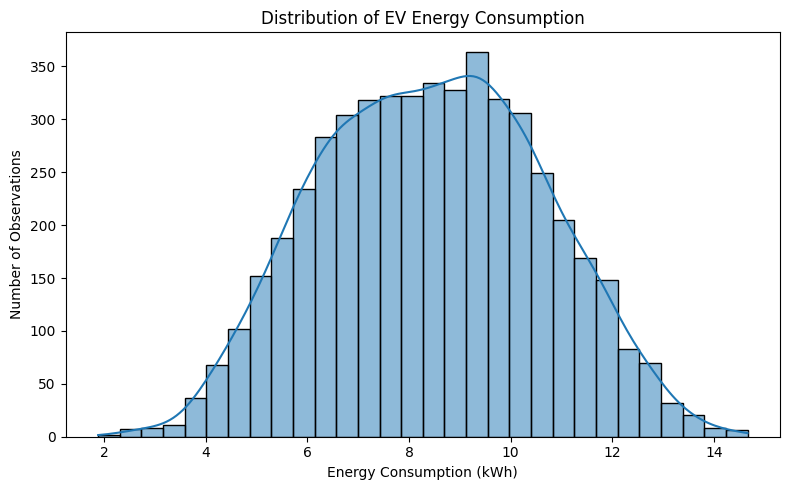

In [4]:
# Plot the distribution of the target variable.
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x=target,
    bins=30,
    kde=True
)

plt.title("Distribution of EV Energy Consumption")
plt.xlabel("Energy Consumption (kWh)")
plt.ylabel("Number of Observations")
plt.tight_layout()
plt.show()

## Energy Consumption by Categorical Features

The boxplots compare energy consumption between the values of each categorical feature.

They show differences in median, spread, and possible extreme values. The category numbers are codes, so they should not be given a real-world meaning without a data dictionary.

**Result:** Four comparison plots were generated successfully.

**Next step:** Examine relationships between numerical features and energy consumption.

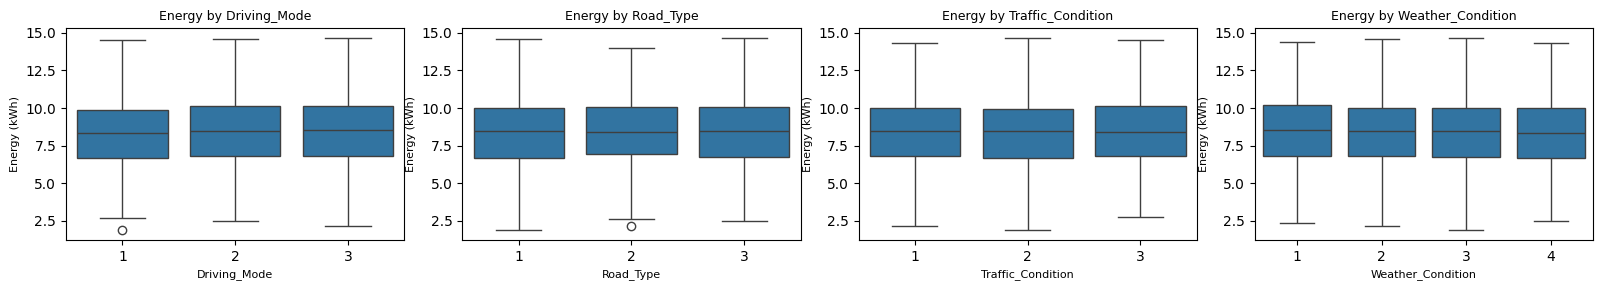

In [5]:
fig, axes = plt.subplots(1, len(categorical_columns), figsize=(16, 3))

for ax, col in zip(axes, categorical_columns):
    sns.boxplot(data=df, x=col, y=target, ax=ax)

    ax.set_title(f"Energy by {col}", fontsize=9)
    ax.set_xlabel(col, fontsize=8)
    ax.set_ylabel("Energy (kWh)", fontsize=8)

plt.tight_layout()
plt.show()

## Relationships Between Numerical Features and the Target

The scatterplots show whether numerical features move together with energy consumption.

A visible pattern indicates an association only. It does not prove that the feature causes the change in energy consumption.

**Result:** The numerical relationship plots were generated successfully.

**Next step:** Calculate and rank the numerical correlations.

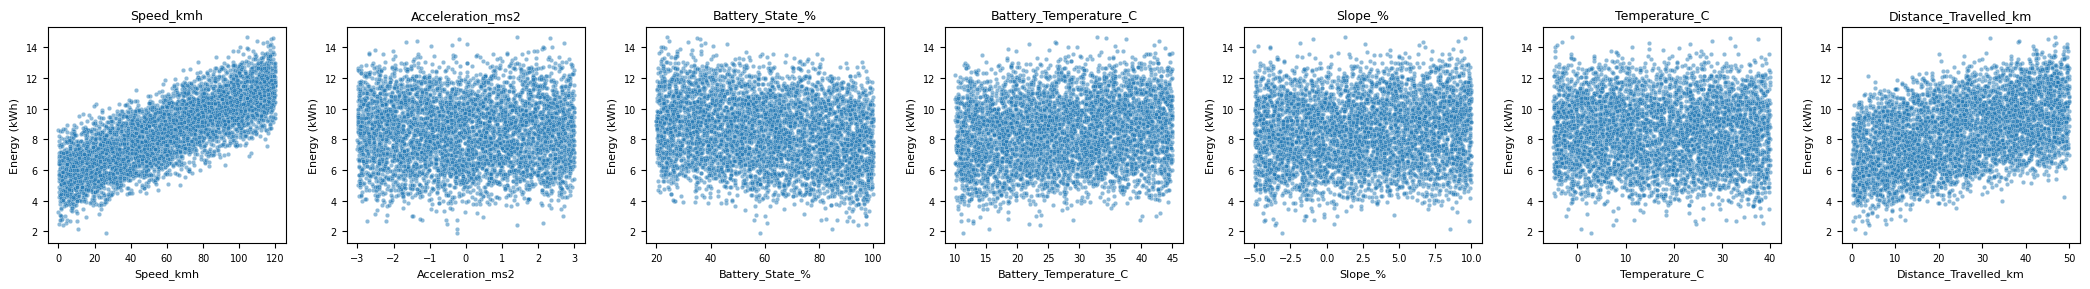

In [6]:
# List of numerical features to plot against energy consumption.
numeric_to_plot = [
    "Speed_kmh",
    "Acceleration_ms2",
    "Battery_State_%",
    "Battery_Temperature_C",
    "Slope_%",
    "Temperature_C",
    "Distance_Travelled_km"
]

# Create one row containing all scatterplots.
fig, axes = plt.subplots(1, len(numeric_to_plot), figsize=(21, 3))

# Plot each numerical feature against energy consumption.
for ax, col in zip(axes, numeric_to_plot):

    sns.scatterplot(
        data=df,
        x=col,
        y=target,
        alpha=0.5,
        s=10,
        ax=ax
    )

    # Set a compact title and axis labels.
    ax.set_title(f"{col}", fontsize=9)
    ax.set_xlabel(col, fontsize=8)
    ax.set_ylabel("Energy (kWh)", fontsize=8)
    ax.tick_params(axis="both", labelsize=7)

# Adjust spacing between plots.
plt.tight_layout()
plt.show()

# 5. Correlation Analysis

Correlation measures the strength and direction of a linear relationship with the target:

- A positive value means both variables tend to increase together.
- A negative value means one tends to decrease as the other increases.
- A value near zero means a weak linear relationship.

**Main results:**

- `Speed_kmh`: **0.793**, the strongest positive correlation.
- `Distance_Travelled_km`: **0.466**, a moderate positive correlation.
- `Battery_State_%`: **-0.214**, a weak negative correlation.
- The remaining features have weak linear correlations with the target.

Correlation is useful for inspection, but it does not prove causation.

**Next step:** Check for possible outliers using the IQR method.

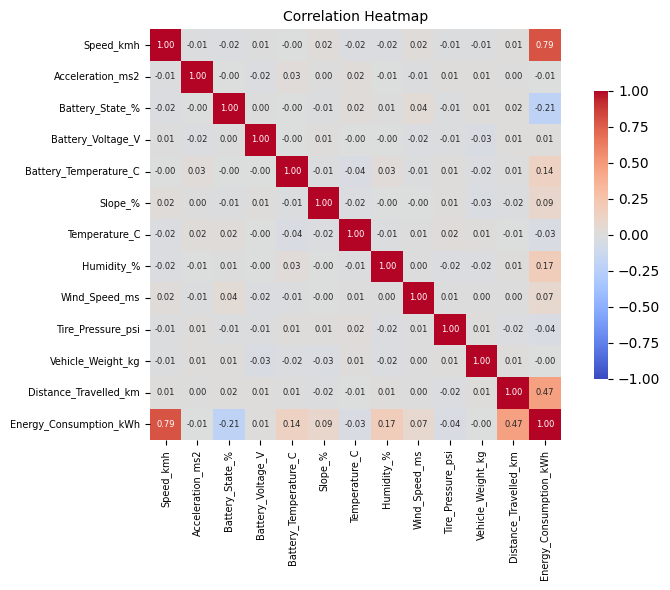

,Correlation_with_Target
Speed_kmh,0.792811
Distance_Travelled_km,0.465870
Battery_State_%,-0.213832
Humidity_%,0.172985
Battery_Temperature_C,0.141392
Slope_%,0.086668
Wind_Speed_ms,0.073352
Tire_Pressure_psi,-0.036304
Temperature_C,-0.033740
Battery_Voltage_V,0.010096


In [7]:
# Select continuous numerical features and the target.
continuous_columns = [
    "Speed_kmh",
    "Acceleration_ms2",
    "Battery_State_%",
    "Battery_Voltage_V",
    "Battery_Temperature_C",
    "Slope_%",
    "Temperature_C",
    "Humidity_%",
    "Wind_Speed_ms",
    "Tire_Pressure_psi",
    "Vehicle_Weight_kg",
    "Distance_Travelled_km",
    target
]

# Keep only columns that exist in the dataset.
continuous_columns = [
    col for col in continuous_columns if col in df
]

# Calculate Pearson correlations.
correlation_matrix = df[continuous_columns].corr(numeric_only=True)

# Display a smaller correlation heatmap.
plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    fmt=".2f",
    annot_kws={"size": 6},
    square=True,
    cbar_kws={"shrink": 0.7}
)

plt.title("Correlation Heatmap", fontsize=10)
plt.xticks(fontsize=7, rotation=90)
plt.yticks(fontsize=7, rotation=0)
plt.tight_layout()
plt.show()

# Rank features by absolute correlation with the target.
target_correlations = (
    correlation_matrix[target]
    .drop(target)
    .sort_values(
        key=lambda values: values.abs(),
        ascending=False
    )
)

# Display correlations with energy consumption.
display(
    target_correlations.to_frame(
        "Correlation_with_Target"
    )
)

# 6. Outlier Inspection

The Interquartile Range (IQR) method identifies values outside the expected range:

- Lower bound = Q1 - 1.5 ? IQR
- Upper bound = Q3 + 1.5 ? IQR

This step only inspects the data. It does not automatically delete observations.

**Result:** All inspected numerical columns and the target have 0 detected IQR outliers.

**Next step:** Create useful time-based features from `Timestamp`.

In [8]:
# Create a list to store outlier statistics.
outlier_results = []

# Inspect continuous numerical columns using the IQR method.
for col in continuous_columns:

    # Calculate the first quartile.
    q1 = df[col].quantile(0.25)

    # Calculate the third quartile.
    q3 = df[col].quantile(0.75)

    # Calculate the interquartile range.
    iqr = q3 - q1

    # Calculate the lower outlier boundary.
    lower_bound = q1 - 1.5 * iqr

    # Calculate the upper outlier boundary.
    upper_bound = q3 + 1.5 * iqr

    # Count observations outside the boundaries.
    outlier_count = (
        (df[col] < lower_bound) |
        (df[col] > upper_bound)
    ).sum()

    # Store the results.
    outlier_results.append({
        "Feature": col,
        "Lower_Bound": lower_bound,
        "Upper_Bound": upper_bound,
        "Outlier_Count": int(outlier_count)
    })

# Convert the results into a DataFrame.
outlier_summary = pd.DataFrame(outlier_results)

# Display the potential outliers.
display(outlier_summary)

,Feature,Lower_Bound,Upper_Bound,Outlier_Count
0,Speed_kmh,-59.756502,178.301903,0
1,Acceleration_ms2,-5.936432,5.920079,0
2,Battery_State_%,-20.394098,140.892344,0
3,Battery_Voltage_V,252.581388,450.000192,0
4,Battery_Temperature_C,-6.668387,61.473291,0
5,Slope_%,-12.639618,17.770955,0
6,Temperature_C,-28.059841,62.634338,0
7,Humidity_%,-14.049007,124.670746,0
8,Wind_Speed_ms,-7.342580,22.471602,0
9,Tire_Pressure_psi,24.546979,38.482257,0


# 7. Feature Engineering

The timestamp is used to create two new features:

- `Hour_of_Day`: the hour from 0 to 23.
- `Day_of_Week`: Monday is 0 and Sunday is 6.

The raw timestamp is kept for chronological splitting but is removed from the model inputs later.

**Result:** 0 timestamps failed to parse, and the new time features were created successfully.

**Next step:** Separate the input features from the target.

In [9]:
df["Timestamp"] = pd.to_datetime(
    df["Timestamp"],
    errors="coerce"
)

# Check whether any timestamps failed to parse.
print("Invalid timestamps:", df["Timestamp"].isna().sum())

df["Hour_of_Day"] = df["Timestamp"].dt.hour
df["Day_of_Week"] = df["Timestamp"].dt.dayofweek

display(
    df[
        [
            "Timestamp",
            "Hour_of_Day",
            "Day_of_Week",
            target
        ]
    ].head()
)

Invalid timestamps: 0


,Timestamp,Hour_of_Day,Day_of_Week,Energy_Consumption_kWh
0,2024-01-01 00:00:00,0,0,12.054317
1,2024-01-01 00:01:00,0,0,4.488701
2,2024-01-01 00:02:00,0,0,11.701377
3,2024-01-01 00:03:00,0,0,7.389266
4,2024-01-01 00:04:00,0,0,6.761205


# 8. Prepare Features and Target

The target `Energy_Consumption_kWh` is stored separately in `y`.

The model input `X` excludes:

- The target column, because it is what the model must predict.
- `Vehicle_ID`, because it identifies a vehicle rather than describing its current condition.
- The raw `Timestamp`, because its useful information was extracted into time features.

The remaining columns are divided into numerical and categorical features.

**Result:** There are 18 input features before preprocessing.

**Next step:** Split the records into training and testing data by time.

In [10]:
X = df.drop(
    columns=[
        target,
        "Vehicle_ID",
        "Timestamp"
    ]
)

# Store the target variable separately.
y = df[target].copy()

# Include original categorical columns and engineered time features.
categorical_features = categorical_columns + [
    "Hour_of_Day",
    "Day_of_Week"
]

# Identify numerical columns that are not categorical.
numeric_features = [
    col for col in X.columns
    if col not in categorical_features
]

# Display the selected features.
print("Numerical features:")
print(numeric_features)

print("\nCategorical features:")
print(categorical_features)

Numerical features:
['Speed_kmh', 'Acceleration_ms2', 'Battery_State_%', 'Battery_Voltage_V', 'Battery_Temperature_C', 'Slope_%', 'Temperature_C', 'Humidity_%', 'Wind_Speed_ms', 'Tire_Pressure_psi', 'Vehicle_Weight_kg', 'Distance_Travelled_km']

Categorical features:
['Driving_Mode', 'Road_Type', 'Traffic_Condition', 'Weather_Condition', 'Hour_of_Day', 'Day_of_Week']


# 9.  Feature Importance (Permutation Importance)

Permutation importance estimates how much the selected model's validation performance worsens when one input feature is shuffled. A larger value indicates that the model relies more on that feature for its predictions. This method can be applied to different model types and works with the full preprocessing pipeline.

# We use the validation set for this interpretation and do not use the test set to rank features. Importance indicates predictive usefulness, not causation.


========== TOP 10 FEATURES BY PERMUTATION IMPORTANCE ==========


,Feature,Importance_Mean,Importance_Std
0,Speed_kmh,2.00753,0.03463
1,Distance_Travelled_km,1.06611,0.03160
2,Battery_State_%,0.29455,0.00819
3,Humidity_%,0.25047,0.01702
4,Battery_Temperature_C,0.14924,0.01131
5,Slope_%,0.05507,0.00455
6,Wind_Speed_ms,0.04268,0.00528
7,Road_Type,0.00681,0.00235
8,Driving_Mode,0.00668,0.00412
9,Tire_Pressure_psi,0.00507,0.00164


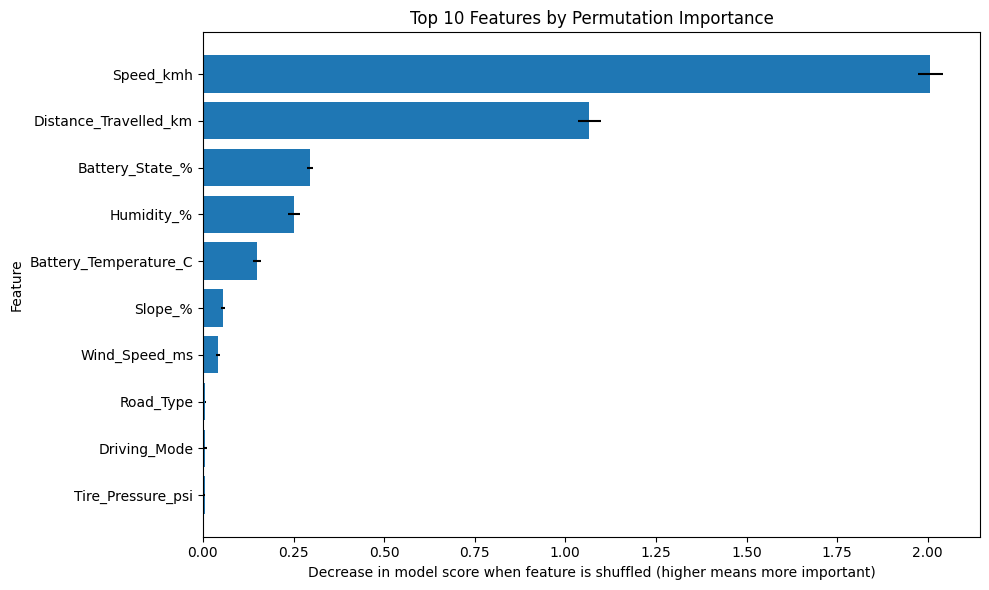

In [28]:
# Measure feature importance for the selected model using validation data.
# Shuffling one feature at a time shows how much prediction quality worsens.
permutation_result = permutation_importance(
    best_model,
    X_val,
    y_val,
    scoring="neg_root_mean_squared_error",
    n_repeats=5,
    random_state=RANDOM_STATE,
    n_jobs=1
)

feature_importance_df = pd.DataFrame({
    "Feature": X_val.columns,
    "Importance_Mean": permutation_result.importances_mean,
    "Importance_Std": permutation_result.importances_std
}).sort_values("Importance_Mean", ascending=False).reset_index(drop=True)

print("\n========== TOP 10 FEATURES BY PERMUTATION IMPORTANCE ==========")
display(feature_importance_df.head(10).round(5))

plt.figure(figsize=(10, 6))
top_features = feature_importance_df.head(10).sort_values("Importance_Mean", ascending=True)
plt.barh(top_features["Feature"], top_features["Importance_Mean"], xerr=top_features["Importance_Std"])
plt.title("Top 10 Features by Permutation Importance")
plt.xlabel("Decrease in model score when feature is shuffled (higher means more important)")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()


# 10. Train / Validation / Test Split

We use train_test_split to divide the rows into:
- 70% Training: used to fit the models.
- 10% Validation: used to compare models and select the best one.
- 20% Testing: kept aside until the final evaluation.

The split is random and reproducible because random_state=42.
If the project must simulate predicting future time periods, use a chronological
split instead. Do not mix the two approaches without explaining the choice.

In [12]:
# Separate features (X) from the target (y).
X = df.drop(
    columns=[target, "Vehicle_ID", "Timestamp"],
    errors="ignore"
).copy()
y = df[target].copy()

# These features are categorical even if their values are represented by codes.
known_categorical = [
    "Driving_Mode",
    "Road_Type",
    "Traffic_Condition",
    "Weather_Condition",
    "Hour_of_Day",
    "Day_of_Week"
]
categorical_features = [col for col in known_categorical if col in X.columns]
numeric_features = [
    col for col in X.columns
    if col not in categorical_features
]

print("Numerical features:", numeric_features)
print("Categorical features:", categorical_features)

# First, reserve 30% for validation + testing.
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=RANDOM_STATE
)

# Split the remaining 30% into 10% validation and 20% testing.
# Within X_temp, validation is 1/3 and test is 2/3.
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=2/3, random_state=RANDOM_STATE
)

total_rows = len(X)
print("\n========== DATA SPLIT ==========")
print(f"Training:   {len(X_train):,} rows ({len(X_train) / total_rows:.1%})")
print(f"Validation: {len(X_val):,} rows ({len(X_val) / total_rows:.1%})")
print(f"Testing:    {len(X_test):,} rows ({len(X_test) / total_rows:.1%})")

# Confirm that no row is shared across splits.
assert set(X_train.index).isdisjoint(X_val.index)
assert set(X_train.index).isdisjoint(X_test.index)
assert set(X_val.index).isdisjoint(X_test.index)
print("Split check passed: no overlap between the three sets.")

# 10. Preprocessing pipeline

Numerical features: ['Speed_kmh', 'Acceleration_ms2', 'Battery_State_%', 'Battery_Voltage_V', 'Battery_Temperature_C', 'Slope_%', 'Temperature_C', 'Humidity_%', 'Wind_Speed_ms', 'Tire_Pressure_psi', 'Vehicle_Weight_kg', 'Distance_Travelled_km']
Categorical features: ['Driving_Mode', 'Road_Type', 'Traffic_Condition', 'Weather_Condition', 'Hour_of_Day', 'Day_of_Week']

========== DATA SPLIT ==========
Training:   3,500 rows (70.0%)
Validation: 500 rows (10.0%)
Testing:    1,000 rows (20.0%)
Split check passed: no overlap between the three sets.


Preprocessing is fitted only on training data through the sklearn Pipeline.
This prevents validation/test information from leaking into imputation,
encoding, or scaling.

In [13]:
numeric_preprocessor = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_preprocessor = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("numeric", numeric_preprocessor, numeric_features),
    ("categorical", categorical_preprocessor, categorical_features)
])

# 11. Define regression models to compare

Regression is appropriate because Energy_Consumption_kWh is a continuous
numeric target. We compare a simple baseline, linear models, and tree-based
models. The validation RMSE is the primary selection metric (lower is better).

In [16]:
models = {
    "Linear Regression": LinearRegression(),
    "KNN Regressor": KNeighborsRegressor(n_neighbors=5),
    "Decision Tree": DecisionTreeRegressor(
        max_depth=8, min_samples_leaf=5, random_state=RANDOM_STATE
    ),
    "Random Forest": RandomForestRegressor(
        n_estimators=150, max_depth=12, min_samples_leaf=3,
        random_state=RANDOM_STATE, n_jobs=-1
    )
}

## 11. Cross-Validation on the Training Set

Cross-validation gives a more reliable estimate of model performance by training and validating each model across five different folds. Only the training split is used here; the validation and test sets remain separate. Lower RMSE and MAE are better, while higher R² is better.

We use the same preprocessing pipeline inside each fold to prevent information leakage.


Running 5-fold cross-validation: Linear Regression
Running 5-fold cross-validation: KNN Regressor
Running 5-fold cross-validation: Decision Tree
Running 5-fold cross-validation: Random Forest

========== 5-FOLD CROSS-VALIDATION RESULTS ==========


,Model,CV_RMSE_Mean,CV_RMSE_Std,CV_MAE_Mean,CV_R2_Mean
0,Linear Regression,0.5214,0.0100,0.4164,0.9425
1,Random Forest,0.6596,0.0078,0.5273,0.9080
2,Decision Tree,0.8661,0.0139,0.6923,0.8413
3,KNN Regressor,1.1106,0.0107,0.8979,0.7392


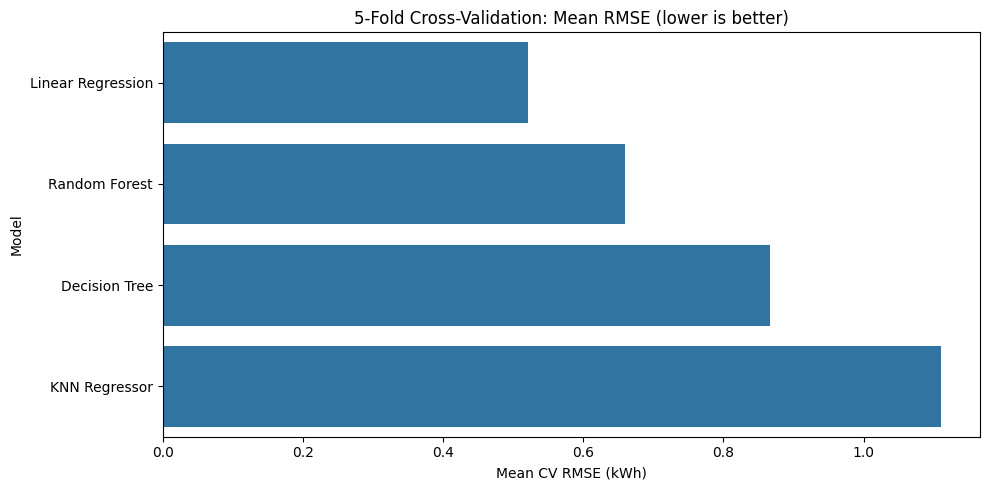

In [17]:
# Evaluate every candidate model using 5-fold cross-validation on the training set only.
# Negative RMSE/MAE are returned by scikit-learn, so multiply by -1 for readable positive errors.
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_results = []

for name, model in models.items():
    print(f"Running 5-fold cross-validation: {name}")

    pipeline = Pipeline(steps=[
        ("preprocessing", preprocessor),
        ("model", model)
    ])

    try:
        scores = cross_validate(
            pipeline,
            X_train,
            y_train,
            cv=cv,
            scoring={
                "rmse": "neg_root_mean_squared_error",
                "mae": "neg_mean_absolute_error",
                "r2": "r2"
            },
            n_jobs=1,
            error_score="raise"
        )

        cv_results.append({
            "Model": name,
            "CV_RMSE_Mean": -scores["test_rmse"].mean(),
            "CV_RMSE_Std": scores["test_rmse"].std(),
            "CV_MAE_Mean": -scores["test_mae"].mean(),
            "CV_R2_Mean": scores["test_r2"].mean()
        })
    except Exception as error:
        print(f"Cross-validation failed for {name}: {error}")

cv_results_df = pd.DataFrame(cv_results).sort_values(
    by="CV_RMSE_Mean", ascending=True
).reset_index(drop=True)

print("\n========== 5-FOLD CROSS-VALIDATION RESULTS ==========")
display(cv_results_df.round(4))

plt.figure(figsize=(10, 5))
sns.barplot(data=cv_results_df, x="CV_RMSE_Mean", y="Model")
plt.title("5-Fold Cross-Validation: Mean RMSE (lower is better)")
plt.xlabel("Mean CV RMSE (kWh)")
plt.ylabel("Model")
plt.tight_layout()
plt.show()


In [36]:
# 12. Train every model and evaluate it on validation data.

results = []
trained_models = {}

for name, model in models.items():
    print(f"\nTraining: {name}")

    pipeline = Pipeline(steps=[
        ("preprocessing", preprocessor),
        ("model", model)
    ])

    try:
        pipeline.fit(X_train, y_train)
        val_predictions = pipeline.predict(X_val)

        mae = mean_absolute_error(y_val, val_predictions)
        rmse = np.sqrt(mean_squared_error(y_val, val_predictions))
        r2 = r2_score(y_val, val_predictions)

        results.append({
            "Model": name,
            "MAE": mae,
            "RMSE": rmse,
            "R2": r2
        })
        trained_models[name] = pipeline

        print(f"Validation MAE:  {mae:.4f} kWh")
        print(f"Validation RMSE: {rmse:.4f} kWh")
        print(f"Validation R2:   {r2:.4f}")

    except Exception as error:
        print(f"Model failed: {name}")
        print(f"Reason: {error}")


Training: Linear Regression
Validation MAE:  0.3945 kWh
Validation RMSE: 0.4969 kWh
Validation R2:   0.9516

Training: KNN Regressor
Validation MAE:  0.9050 kWh
Validation RMSE: 1.1350 kWh
Validation R2:   0.7474

Training: Decision Tree
Validation MAE:  0.7008 kWh
Validation RMSE: 0.8880 kWh
Validation R2:   0.8454

Training: Random Forest
Validation MAE:  0.5190 kWh
Validation RMSE: 0.6570 kWh
Validation R2:   0.9154


In [30]:
# 14. Compare models and choose the best validation RMSE.

results_df = pd.DataFrame(results)
if results_df.empty:
    raise RuntimeError("No model was successfully trained.")

results_df = results_df.sort_values(
    by="RMSE", ascending=True
).reset_index(drop=True)

print("\n========== VALIDATION MODEL COMPARISON ==========")
display(results_df.round(4))

best_model_name = results_df.loc[0, "Model"]
best_model = trained_models[best_model_name]

print("\nSelected model:", best_model_name)
print(f"Best validation RMSE: {results_df.loc[0, 'RMSE']:.4f} kWh")



========== VALIDATION MODEL COMPARISON ==========


,Model,MAE,RMSE,R2
0,Linear Regression,0.3945,0.4969,0.9516
1,Random Forest,0.5190,0.6570,0.9154
2,Decision Tree,0.7008,0.8880,0.8454
3,KNN Regressor,0.9050,1.1350,0.7474



Selected model: Linear Regression
Best validation RMSE: 0.4969 kWh


In [31]:
# 15. Evaluate the selected model on the test set only after selection.

test_predictions = best_model.predict(X_test)
test_mae = mean_absolute_error(y_test, test_predictions)
test_rmse = np.sqrt(mean_squared_error(y_test, test_predictions))
test_r2 = r2_score(y_test, test_predictions)

print("\n========== FINAL TEST RESULTS ==========")
print("Selected model:", best_model_name)
print(f"Test MAE:  {test_mae:.4f} kWh")
print(f"Test RMSE: {test_rmse:.4f} kWh")
print(f"Test R2:   {test_r2:.4f}")


========== FINAL TEST RESULTS ==========
Selected model: Linear Regression
Test MAE:  0.4070 kWh
Test RMSE: 0.5056 kWh
Test R2:   0.9458



First 10 test predictions:


,Actual_Energy_kWh,Predicted_Energy_kWh
790,10.752,10.663
2879,8.862,8.731
2372,10.050,9.607
1351,12.799,13.307
3382,6.283,6.068
3433,8.448,8.972
1129,12.804,12.852
549,5.897,5.389
2835,7.261,7.498
626,5.081,5.506


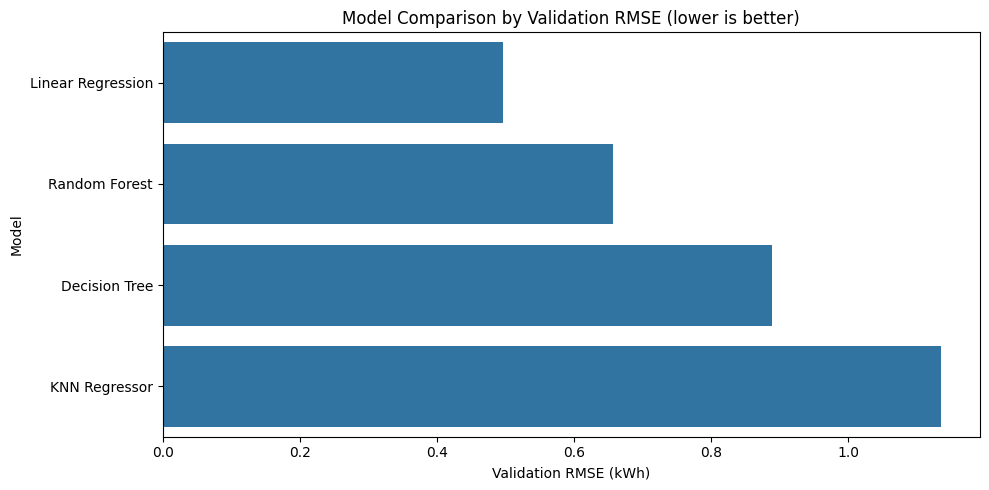

In [32]:
# 16. Compare actual and predicted values.

comparison = pd.DataFrame({
    "Actual_Energy_kWh": np.asarray(y_test),
    "Predicted_Energy_kWh": test_predictions
}, index=y_test.index)

print("\nFirst 10 test predictions:")
display(comparison.head(10).round(3))

# Optional: visualize the best model's validation RMSE comparison.
plt.figure(figsize=(10, 5))
sns.barplot(data=results_df, x="RMSE", y="Model")
plt.title("Model Comparison by Validation RMSE (lower is better)")
plt.xlabel("Validation RMSE (kWh)")
plt.ylabel("Model")
plt.tight_layout()
plt.show()